In [ ]:

pip install pandas pyxlsb

In [ ]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
data_path = '/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code'

In [ ]:
import re
from datetime import datetime

def is_valid_time(time_string):
    try:
        # Attempt to parse the string as a time with the format HH:MM:SS
        datetime.strptime(time_string, "%H:%M:%S")
        return True
    except ValueError:
        # If parsing fails, the format is invalid
        return False

def check_values(array):
  for item in array:
    # Check if any value is NaN or empty
    if pd.isna(item) or str(item).strip() == '':
      return False
  return True

def extract_data(file_path):
  df = pd.read_excel(file_path, header=0)

  values = []

  for i, c in enumerate(df.columns):
    for j, value in enumerate(df[c]):
      if is_valid_time(str(value)):
        try:
          time = df.at[j, df.columns[i]]
          concentration = df.at[j, df.columns[i + 1]]
          count = df.at[j, df.columns[i + 2]]

          if (check_values([time, concentration, count])):
            values.append([time, concentration, count])
        except:
          continue

  return values

Run everything above before starting data analysis below

In [ ]:
"Data for : "

data1 = extract_data('/content/drive/Shared drives/EARL/Students/Kaitlyn/Excel Files and Code/2025_TRENDY_COUNT_3_RUN_3.xlsx')
print(len(data1))
concentration1 = []

for i in range(len(data1)):
   concentration1.append(data1[i][1])

print(concentration1)
print(len(concentration1))

time1 = np.arange(0, len(concentration1), 1)
print(time1)

dconc_dt_1 = np.gradient(concentration1, time1)

1615
[643.4, 679.7, 604.9, 636.6, 601.6, 634.2, 666.1, 574.4, 635.3, 566.4, 539.2, 625.2, 547.8, 574.8, 619.9, 691.2, 765.6, 738.7, 652.5, 692.9, 664.1, 701.3, 669.4, 669.5, 23646, 287900, 815700, 1000000, 997500, 976000, 995800, 1000000, 1000000, 1000000, 1000000, 1000000, 991400, 915200, 865500, 851100, 855700, 871100, 869800, 850800, 826300, 810000, 807600, 806000, 788600, 777400, 776500, 785100, 787000, 799300, 797300, 791700, 787400, 775700, 768000, 762200, 752100, 744000, 736700, 727600, 724400, 724700, 717500, 712800, 709100, 709800, 711800, 712100, 700300, 693300, 688700, 686900, 684000, 676900, 668700, 666500, 666500, 661900, 660400, 664900, 665800, 661000, 656000, 651600, 642000, 638600, 640900, 635000, 628800, 629100, 628800, 625000, 618900, 618100, 612300, 612500, 610400, 607200, 609900, 606500, 600100, 598000, 593200, 592200, 590100, 584600, 581100, 577500, 575200, 571300, 573600, 567000, 562700, 557800, 557400, 559000, 557100, 553900, 553100, 551600, 545300, 544100, 54340

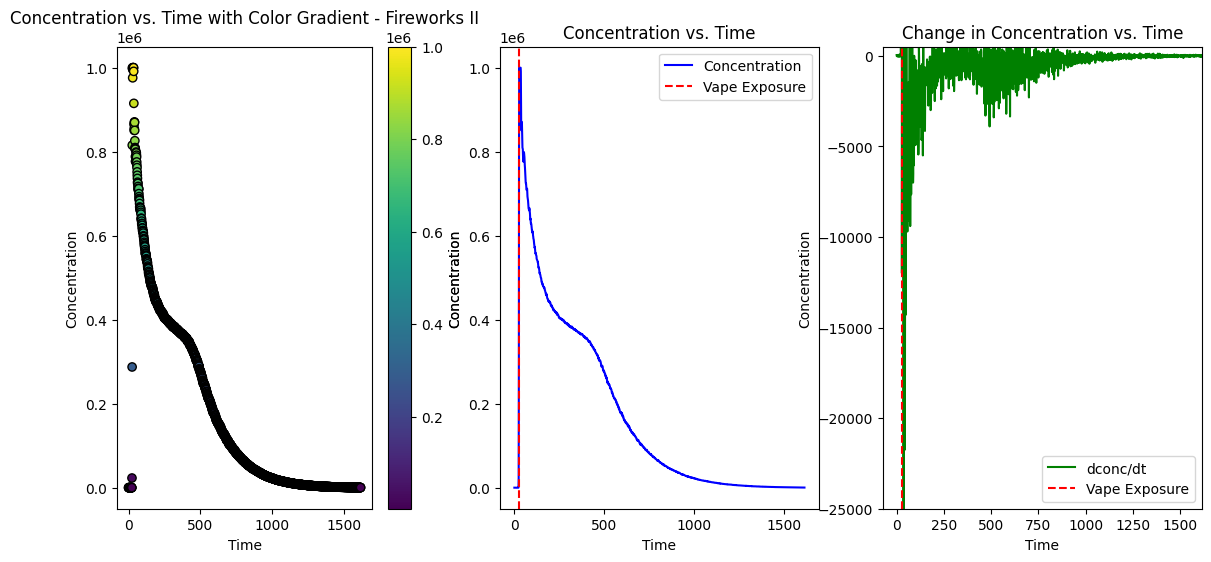

In [ ]:

max_index_1 = np.argmax(concentration1)
max_time_1 = time1[max_index_1]

# Create a figure with two subplots
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Scatter plot with color gradient
scatter = axs[0].scatter(time1, concentration1, c=concentration1, cmap='viridis', edgecolor='k')
axs[0].set_title('Concentration vs. Time with Color Gradient - Fireworks II')
axs[0].set_xlabel('Time')
axs[0].set_ylabel('Concentration')
fig.colorbar(scatter, ax=axs[0], label='Concentration')


# Line plot of concentration over time
axs[1].plot(time1, concentration1, label='Concentration', color='blue')
axs[1].set_title('Concentration vs. Time')
axs[1].set_xlabel('Time')
axs[1].set_ylabel('Concentration')
axs[1].axvline(max_time_1, color='red', linestyle='--', label='Vape Exposure')
axs[1].legend()



#Line plot of change in concentration over time
axs[2].plot(time1, dconc_dt_1, label='dconc/dt', color='green')
axs[2].set_title('Change in Concentration vs. Time')
axs[2].set_xlabel('Time')
axs[2].set_ylabel('Concentration')
axs[2].axvline(max_time_1, color='red', linestyle='--', label='Vape Exposure')
axs[2].set_xlim(max_time_1-100, len(concentration1))
axs[2].set_ylim(-25000, 500)
axs[2].legend()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Exponential decay model ---
def exp_decay(t, A, k, C):
    return A * np.exp(-k * t) + C

# --- 1. Identify vape exposure (max concentration index) ---
max_index = np.argmax(concentration1)
phase_one_start = max_index

# Apply 30s buffer to phase one start
phase_one_start_time = time1[phase_one_start] + 30  # Add 30s buffer
phase_one_start = np.where(time1 >= phase_one_start_time)[0][0]

# --- 2. Derivatives for inflection candidates ---
dconc_dt = np.gradient(concentration1, time1)
d2conc_dt2 = np.gradient(dconc_dt, time1)

# --- 3. Find inflection points after vape exposure + 100s ---
inflection_candidates = np.where(np.diff(np.sign(d2conc_dt2)))[0]
inflection_candidates = inflection_candidates[inflection_candidates > phase_one_start + 100]

best_error = np.inf
best_split = None
best_popt_p1 = None
best_popt_p2 = None

# --- 4. Test each inflection candidate and compute total error ---
for candidate in inflection_candidates:
    t_p1, c_p1 = time1[phase_one_start:candidate], concentration1[phase_one_start:candidate]
    t_p2, c_p2 = time1[candidate:], concentration1[candidate:]

    if len(t_p1) < 5 or len(t_p2) < 5:
        continue

    try:
        popt_p1, _ = curve_fit(exp_decay, t_p1, c_p1, p0=(1e6, 0.01, 1e5),
                               bounds=([0, 0, 0], [np.inf, np.inf, np.inf]), maxfev=10000)
        popt_p2, _ = curve_fit(exp_decay, t_p2, c_p2, p0=(1e6, 0.005, 1e5),
                               bounds=([0, 0, 0], [np.inf, np.inf, np.inf]), maxfev=10000)

        err_p1 = np.sum((c_p1 - exp_decay(t_p1, *popt_p1))**2)
        err_p2 = np.sum((c_p2 - exp_decay(t_p2, *popt_p2))**2)
        total_error = err_p1 + err_p2

        if total_error < best_error:
            best_error = total_error
            best_split = candidate
            best_popt_p1 = popt_p1
            best_popt_p2 = popt_p2
    except:
        continue

# --- 5. Assign best split with e-folding buffer ---
if best_split is not None:
    inflection_time = time1[best_split]

    # Compute τ (e-folding times) and cap them to avoid excessive shift
    tau_top = min(1 / best_popt_p1[1], 50)      # cap at 50s
    tau_bottom = min(1 / best_popt_p2[1], 50)

    # Buffer before and after inflection
    phase_one_end_time = max(phase_one_start_time + 1, inflection_time - tau_top)
    phase_two_start_time = inflection_time + tau_bottom

    # Convert buffered times to indices
    phase_one_end = np.where(time1 >= phase_one_end_time)[0][0]
    phase_two_start = np.where(time1 >= phase_two_start_time)[0][0]

    # Ensure valid ordering
    if phase_one_end <= phase_one_start:
        phase_one_end = best_split - 1
    if phase_two_start <= phase_one_end:
        phase_two_start = best_split
else:
    # Fallback: no inflection found
    phase_one_end = phase_one_start + 100
    phase_two_start = phase_one_end

# --- 6. Phase Two end: first index <= 999 ---
phase_two_candidates = np.where(np.array(concentration1) <= 999)[0]
phase_two_candidates = phase_two_candidates[phase_two_candidates > phase_two_start]
phase_two_end = phase_two_candidates[0] if len(phase_two_candidates) > 0 else len(concentration1) - 1

# --- Print results ---
print(f"Phase One: Start={phase_one_start}, End={phase_one_end}")
print(f"Phase Two: Start={phase_two_start}, End={phase_two_end}")


Phase One: Start=57, End=393
Phase Two: Start=493, End=1593


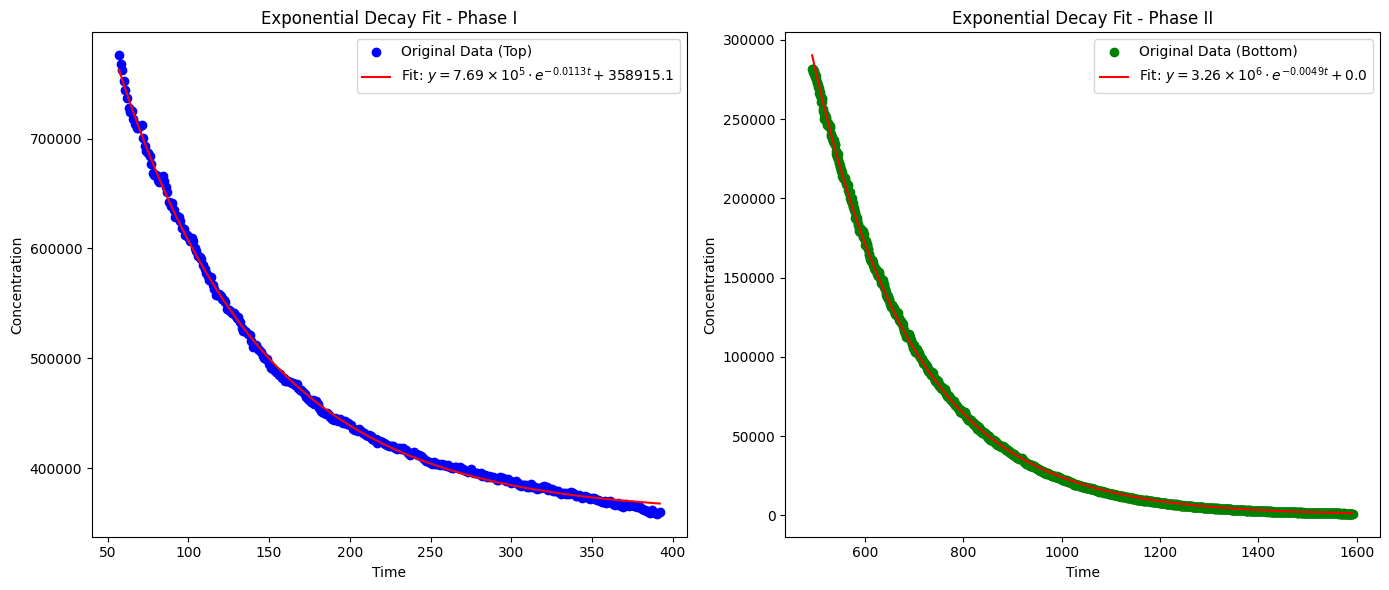

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Step 1: Define exponential decay model
def exp_decay(t, A, k, C):
    return A * np.exp(-k * t) + C

# Step 2: Load your actual data here
# Example:
# time1 = np.array([...])
# concentration1 = np.array([...])

# Step 3: Define cutoff points
top_start = 57
top_end = 393
bottom_start = 493
bottom_end = 1593

# Step 4: Slice data
t_top = time1[top_start:top_end]
c_top = concentration1[top_start:top_end]
t_bottom = time1[bottom_start:bottom_end]
c_bottom = concentration1[bottom_start:bottom_end]

# Step 5: Fit exponential decay to both regions with bounds (to keep C ≥ 0)
bounds = ([0, 0, 0], [np.inf, np.inf, np.inf])

popt_top, _ = curve_fit(exp_decay, t_top, c_top, p0=(1e6, 0.01, 1e5), bounds=bounds, maxfev=10000)
fit_top = exp_decay(t_top, *popt_top)

popt_bottom, _ = curve_fit(exp_decay, t_bottom, c_bottom, p0=(1e6, 0.005, 1e5), bounds=bounds, maxfev=10000)
fit_bottom = exp_decay(t_bottom, *popt_bottom)

# Step 6: Plotting
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Function to format coefficient in LaTeX scientific notation
def sci_notation_latex(num):
    coeff = f"{num:.2e}".split("e")[0]
    exponent = int(f"{num:.2e}".split("e")[1])
    return rf"{coeff} \times 10^{{{exponent}}}"

# LaTeX-formatted equations for legend
top_eq = rf'Fit: $y = {sci_notation_latex(popt_top[0])} \cdot e^{{-{popt_top[1]:.4f}t}} + {popt_top[2]:.1f}$'
bottom_eq = rf'Fit: $y = {sci_notation_latex(popt_bottom[0])} \cdot e^{{-{popt_bottom[1]:.4f}t}} + {popt_bottom[2]:.1f}$'


# Top plot
ax[0].scatter(t_top, c_top, label='Original Data (Top)', color='blue')
ax[0].plot(t_top, fit_top, label=top_eq, color='red')
ax[0].set_title("Exponential Decay Fit - Phase I")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Concentration")
ax[0].legend()

# Bottom plot
ax[1].scatter(t_bottom, c_bottom, label='Original Data (Bottom)', color='green')
ax[1].plot(t_bottom, fit_bottom, label=bottom_eq, color='red')
ax[1].set_title("Exponential Decay Fit - Phase II")
ax[1].set_xlabel("Time")
ax[1].set_ylabel("Concentration")
ax[1].legend()

plt.tight_layout()
plt.show()

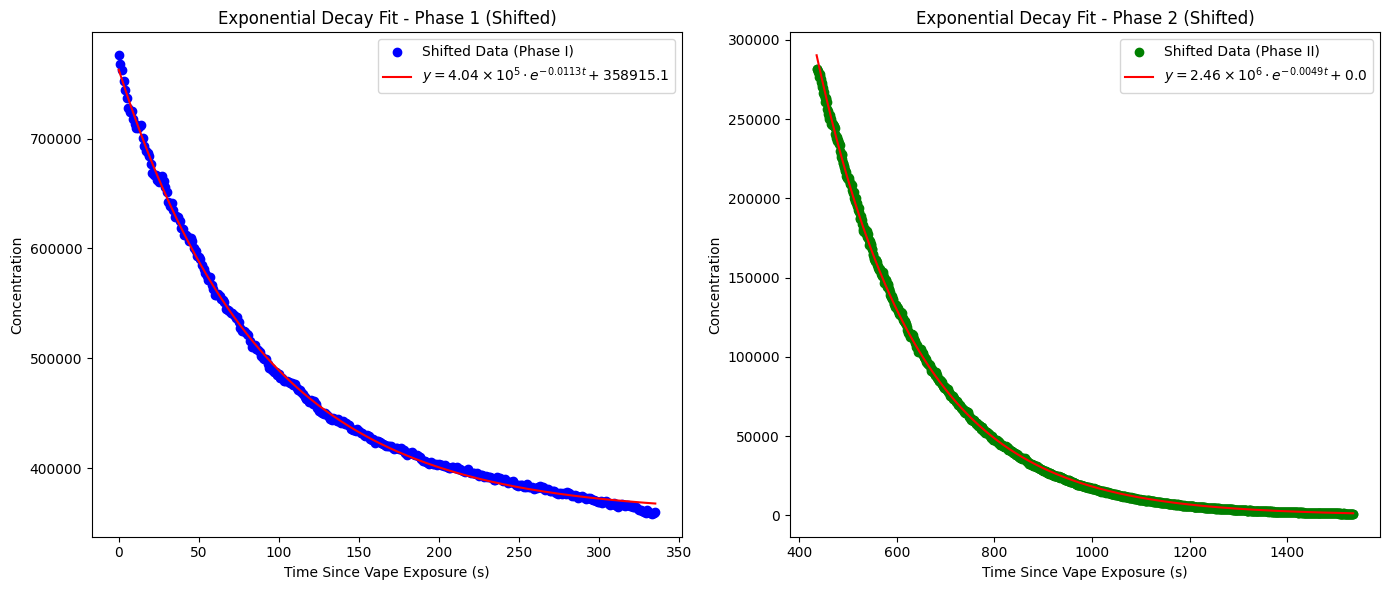

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# --- Exponential decay model ---
def exp_decay(t, A, k, C):
    return A * np.exp(-k * t) + C

# --- Vape exposure time ---
vape_exposure_time = time1[phase_one_start]  # time at max concentration

# --- Shift times so that vape exposure = 0 ---
t_top_shifted = t_top - vape_exposure_time
t_bottom_shifted = t_bottom - vape_exposure_time

# --- Refit the shifted data ---
popt_top_shifted, _ = curve_fit(exp_decay, t_top_shifted, c_top, p0=(1e6, 0.01, 1e5), bounds=([0, 0, 0], [np.inf, np.inf, np.inf]), maxfev=10000)
fit_top_shifted = exp_decay(t_top_shifted, *popt_top_shifted)

popt_bottom_shifted, _ = curve_fit(exp_decay, t_bottom_shifted, c_bottom, p0=(1e6, 0.005, 1e5), bounds=([0, 0, 0], [np.inf, np.inf, np.inf]), maxfev=10000)
fit_bottom_shifted = exp_decay(t_bottom_shifted, *popt_bottom_shifted)

# --- LaTeX formatting for equations ---
def sci_notation_latex(num):
    coeff = f"{num:.2e}".split("e")[0]
    exponent = int(f"{num:.2e}".split("e")[1])
    return rf"{coeff} \times 10^{{{exponent}}}"

top_eq_shifted = rf'$y = {sci_notation_latex(popt_top_shifted[0])} \cdot e^{{-{popt_top_shifted[1]:.4f}t}} + {popt_top_shifted[2]:.1f}$'
bottom_eq_shifted = rf'$y = {sci_notation_latex(popt_bottom_shifted[0])} \cdot e^{{-{popt_bottom_shifted[1]:.4f}t}} + {popt_bottom_shifted[2]:.1f}$'

# --- Plot shifted data ---
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Phase 1 shifted
ax[0].scatter(t_top_shifted, c_top, label="Shifted Data (Phase I)", color="blue")
ax[0].plot(t_top_shifted, fit_top_shifted, "r", label=top_eq_shifted)
ax[0].set_title("Exponential Decay Fit - Phase 1 (Shifted)")
ax[0].set_xlabel("Time Since Vape Exposure (s)")
ax[0].set_ylabel("Concentration")
ax[0].legend(loc="upper right")

# Phase 2 shifted
ax[1].scatter(t_bottom_shifted, c_bottom, label="Shifted Data (Phase II)", color="green")
ax[1].plot(t_bottom_shifted, fit_bottom_shifted, "r", label=bottom_eq_shifted)
ax[1].set_title("Exponential Decay Fit - Phase 2 (Shifted)")
ax[1].set_xlabel("Time Since Vape Exposure (s)")
ax[1].set_ylabel("Concentration")
ax[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


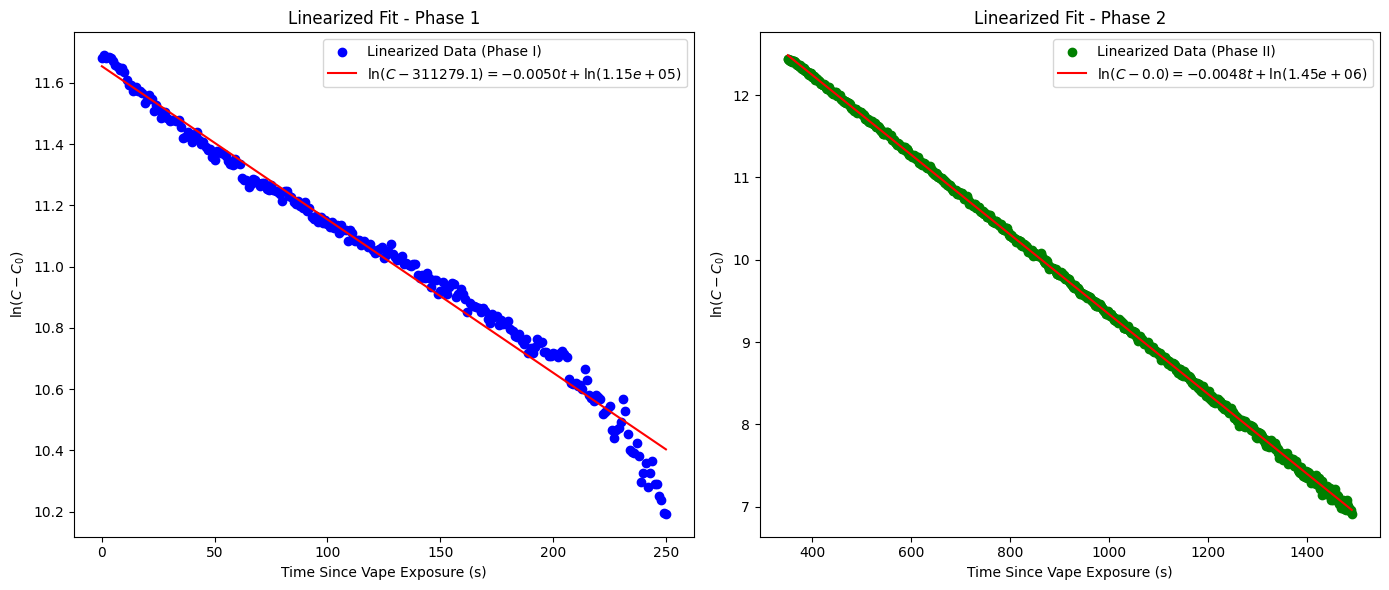

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Phase 1 Linearization ---
y_top = np.log(c_top - popt_top_shifted[2])         # ln(C - C0)
x_top = t_top_shifted

slope_top, intercept_top = np.polyfit(x_top, y_top, 1)
A_top = np.exp(intercept_top)
k_top = -slope_top
C0_top = popt_top_shifted[2]

# --- Phase 2 Linearization ---
y_bottom = np.log(c_bottom - popt_bottom_shifted[2])
x_bottom = t_bottom_shifted

slope_bottom, intercept_bottom = np.polyfit(x_bottom, y_bottom, 1)
A_bottom = np.exp(intercept_bottom)
k_bottom = -slope_bottom
C0_bottom = popt_bottom_shifted[2]

# --- Generate lines ---
fit_line_top = slope_top * x_top + intercept_top
fit_line_bottom = slope_bottom * x_bottom + intercept_bottom

# --- Plot ---
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Phase 1
ax[0].scatter(x_top, y_top, color='blue', label='Linearized Data (Phase I)')
ax[0].plot(x_top, fit_line_top, 'r', label=rf"$\ln(C-{C0_top:.1f})=-{k_top:.4f}t+\ln({A_top:.2e})$")
ax[0].set_title("Linearized Fit - Phase 1")
ax[0].set_xlabel("Time Since Vape Exposure (s)")
ax[0].set_ylabel(r"$\ln(C-C_0)$")
ax[0].legend()

# Phase 2
ax[1].scatter(x_bottom, y_bottom, color='green', label='Linearized Data (Phase II)')
ax[1].plot(x_bottom, fit_line_bottom, 'r', label=rf"$\ln(C-{C0_bottom:.1f})=-{k_bottom:.4f}t+\ln({A_bottom:.2e})$")
ax[1].set_title("Linearized Fit - Phase 2")
ax[1].set_xlabel("Time Since Vape Exposure (s)")
ax[1].set_ylabel(r"$\ln(C-C_0)$")
ax[1].legend()

plt.tight_layout()
plt.show()

